In [76]:
import pandas as pd
from pathlib import Path
import numpy as np

data_dir = Path('../data')

df = pd.read_csv(data_dir/'clean.csv')

df.head()

,Brand,model,Age,kmDriven,Transmission,Owner,FuelType,AskPrice,Brand_avgPrice,Model_avgPrice
0,honda,city,23,98000,0,0,Petrol,195000,5.055770e+05,535442.743640
1,toyota,innova,15,190000,0,0,Diesel,375000,1.738645e+06,835954.760274
2,volkswagen,ventotest,14,77246,0,1,Diesel,184999,6.717446e+05,469052.543860
3,maruti suzuki,swift,7,83500,0,0,Diesel,565000,4.790632e+05,473432.824427
4,maruti suzuki,baleno,5,45000,1,1,Petrol,685000,4.790632e+05,616768.929688


In [77]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [78]:
df.columns

Index(['Brand', 'model', 'Age', 'kmDriven', 'Transmission', 'Owner',
       'FuelType', 'AskPrice', 'Brand_avgPrice', 'Model_avgPrice'],
      dtype='str')

In [79]:
numeric_cols = ['Age', 'kmDriven', 'Brand_avgPrice', 'Model_avgPrice']
binary_cols = ['Owner', 'Transmission']
categoric_cols = ['FuelType']
important_cols = ['Brand', 'model']

In [80]:
# X = df.drop(columns =['AskPrice', 'Brand', 'model'])
X = df.drop(columns =['AskPrice','Brand', 'model'])
y = df['AskPrice']

In [81]:
X.columns

Index(['Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType',
       'Brand_avgPrice', 'Model_avgPrice'],
      dtype='str')

In [82]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)

In [83]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categoric_cols ),
        ('num', 'passthrough', numeric_cols),
        ('bin', 'passthrough', binary_cols)
    ]
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [84]:
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression

lgmodel = LinearRegression()


In [21]:
from sklearn.tree import DecisionTreeRegressor
tree = DecisionTreeRegressor(random_state = 42)

In [30]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['squared_error', 'absolute_error']
}

grid = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)
grid

GridSearchCV(cv=3, estimator=DecisionTreeRegressor(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['squared_error', 'absolute_error'],
                         'max_depth': [3, 5, 7, 10],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='r2')

In [85]:
from sklearn.ensemble import RandomForestRegressor

rfg = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

In [90]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    max_depth = 5,
    learning_rate = 0.1,
    random_state = 42,
    n_jobs = -1
)

In [40]:
from catboost import CatBoostRegressor

cbg = CatBoostRegressor(
    iterations=500,
    learning_rate=0.1,
    depth=6,
    random_state =42,
    verbose = 100
)

In [17]:
lgmodel.fit(X_train_transformed, y_train)

LinearRegression()

In [22]:
tree.fit(X_train_transformed, y_train)

DecisionTreeRegressor(random_state=42)

In [42]:
grid.fit(X_train_transformed, y_train)

GridSearchCV(cv=3, estimator=DecisionTreeRegressor(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['squared_error', 'absolute_error'],
                         'max_depth': [3, 5, 7, 10],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='r2')

In [86]:
rfg.fit(X_train_transformed, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [91]:
xgb.fit(X_train_transformed, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [41]:
cbg.fit(X_train_transformed, y_train)

0:	learn: 1508003.3759499	total: 283ms	remaining: 2m 20s
100:	learn: 386811.9951555	total: 888ms	remaining: 3.51s
200:	learn: 310223.7566361	total: 1.46s	remaining: 2.17s
300:	learn: 274486.7936480	total: 2.01s	remaining: 1.33s
400:	learn: 253146.9701489	total: 2.46s	remaining: 608ms
499:	learn: 238236.4902382	total: 2.97s	remaining: 0us


CatBoostRegressor(depth=6, iterations=500, learning_rate=0.1, loss_function='RMSE', random_state=42, verbose=100)

In [92]:
# y_pred = lgmodel.predict(X_test_transformed)
# y_pred = tree.predict(X_test_transformed)

# best_grid = grid.best_estimator_
# y_pred = best_grid.predict(X_test_transformed)

# y_pred = rfg.predict(X_test_transformed)
y_pred = xgb.predict(X_test_transformed)
# y_pred = cbg.predict(X_test_transformed)

In [93]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error

mae = mean_absolute_error(y_pred, y_test)
mse = mean_squared_error(y_pred, y_test)
rmse = root_mean_squared_error(y_pred, y_test)
r2score = r2_score(y_pred, y_test)
mape = mean_absolute_percentage_error(y_pred, y_test)
accuracy = (1 - mape)*100

print(f"mean absolute error- {mae}")
print(f"mean squared error- {mse}")
print(f"root mean squared error- {rmse}")
print(f"r2 score - {r2score}")
print("accuracy  :", accuracy)

mean absolute error- 201106.03125
mean squared error- 374992076800.0
root mean squared error- 612365.9375
r2 score - 0.8425031304359436
accuracy  : 80.31260371208191


In [75]:
fold = 5
kf = KFold(n_splits=fold, shuffle= True, random_state= 42)

# cross_score = cross_val_score(lgmodel, X_train_transformed, y_train, cv = kf)
# cross_score = cross_val_score(tree, X_train_transformed, y_train, cv = kf)
# cross_score = cross_val_score(best_grid, X_train_transformed, y_train, cv = kf) 
cross_score = cross_val_score(rfg, X_train_transformed, y_train, cv = kf) 
# cross_score = cross_val_score(xgb, X_train_transformed, y_train, cv = kf) 
# cross_score = cross_val_score(cbg, X_train_transformed, y_train, cv = kf) 


for i, result in enumerate(cross_score, 1):
    print(f"  Fold {i}: {result * 100:.2f}%")
    
print(f'Mean Accuracy: {cross_score.mean()* 100:.2f}%')

  Fold 1: 89.57%
  Fold 2: 78.33%
  Fold 3: 85.20%
  Fold 4: 90.47%
  Fold 5: 88.03%
Mean Accuracy: 86.32%


## for linear model--
* mean absolute error- 291654.1748989814
* mean squared error- 454059198364.29944
* root mean squared error- 673839.1487323213
* r2 score - 0.7592620350634719
* accuracy  : 38.80583807976761

* kfold result
  * Fold 1: 86.58%
  * Fold 2: 71.83%
  * Fold 3: 86.49%
  * Fold 4: 84.36%
  * Fold 5: 81.00%
  * Mean Accuracy: 82.05%


## for Normal decisionTree regressor--
* mean absolute error- 207751.18362089625
* mean squared error- 378594822454.0384
* root mean squared error- 615300.5952004584
* r2 score - 0.8554983395559131
* accuracy  : 62.80666800494139

* k-fold --
  * Fold 1: 85.94%
  *  Fold 2: 75.63%
  *  Fold 3: 83.14%
  *  Fold 4: 74.03%
  *  Fold 5: 73.45%
  * Mean Accuracy: 78.44%


## using grid --
* mean absolute error- 202411.05391497814
* mean squared error- 365602436571.8311
* root mean squared error- 604650.6731757033
* r2 score - 0.8403737241819025
* accuracy  : 62.063338461255846

* k-fold -
    * Fold 1: 85.71%
    * Fold 2: 78.98%
    * Fold 3: 84.28%
    * Fold 4: 88.54%
    * Fold 5: 82.28%
    * Mean Accuracy: 83.96%

## using random forest regressor --
* mean absolute error- 170576.2562906105
* mean squared error- 267084609983.99655
* root mean squared error- 516802.2929360865
* r2 score - 0.873203395464202
* accuracy  : 65.51656513386546

* k-fold -
    * Fold 1: 89.57%
    * Fold 2: 78.33%
    * Fold 3: 85.20%
    * Fold 4: 90.47%
    * Fold 5: 88.03%
    * Mean Accuracy: 86.32%

## xgboost --
* mean absolute error- 201106.03125
* mean squared error- 374992076800.0
* root mean squared error- 612365.9375
* r2 score - 0.8425031304359436
* accuracy  : 60.494264960289

* k-fold -- 
    * Fold 1: 82.07%
    * Fold 2: 78.17%
    * Fold 3: 65.80%
    * Fold 4: 86.00%
    * Fold 5: 87.86%
    * Mean Accuracy: 79.98%

## catboost --
* mean absolute error- 175635.9647083033
* mean squared error- 252536245031.88174
* root mean squared error- 502529.8449165798
* r2 score - 0.87994111561329
* accuracy  : 63.65712397044264

* k-fold--
  * Fold 3: 83.18%
  * Fold 4: 88.99%
  * Fold 5: 90.39%
  * Mean Accuracy: 86.37%


<Axes: xlabel='AskPrice'>

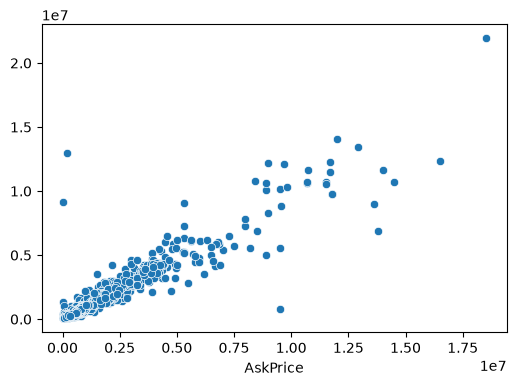

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(6, 4))
sns.scatterplot(x = y_test, y = y_pred)


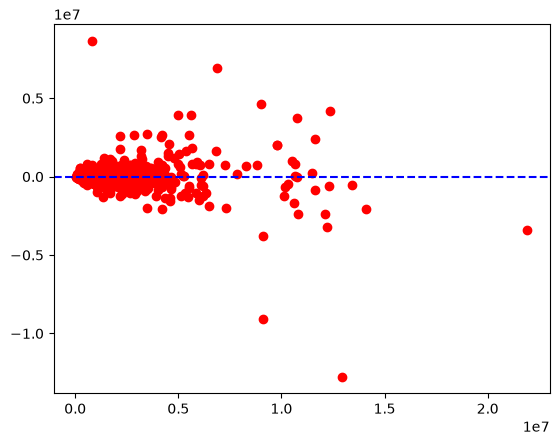

In [56]:
residual = y_test - y_pred

plt.scatter(y_pred, residual, color = 'red')
plt.axhline(y=0, linestyle="--", color = 'blue')
